In [1]:
from data import load_data

es= load_data('ES=F')

es.head()

[*********************100%***********************]  1 of 1 completed


,close,high,low,open,volume
Datetime,,,,,
2026-10-09 00:09:00-04:00,7840.00,7840.25,7839.25,7840.00,0
2026-10-09 00:10:00-04:00,7840.25,7840.25,7839.75,7840.00,36
2026-10-09 00:11:00-04:00,7840.75,7840.75,7840.25,7840.25,96
2026-10-09 00:12:00-04:00,7841.00,7841.00,7840.50,7841.00,100
2026-10-09 00:13:00-04:00,7840.75,7840.75,7840.50,7840.75,78


In [2]:
from sessions import prepare_rth
from indicators import Indicator



es_rth = prepare_rth(es.copy())
ind = Indicator(es_rth)
es_rth["vwap"] = ind.calculate_session_vwap()

print(es_rth[["close", "volume", "vwap"]].tail(10))

                             close  volume         vwap
Datetime                                               
2026-10-16 15:50:00-04:00  7698.00   11314  7734.083347
2026-10-16 15:51:00-04:00  7699.25    6657  7733.954405
2026-10-16 15:52:00-04:00  7702.25    7096  7733.826410
2026-10-16 15:53:00-04:00  7701.25    6310  7733.715719
2026-10-16 15:54:00-04:00  7700.75    9558  7733.550792
2026-10-16 15:55:00-04:00  7702.50   11627  7733.351933
2026-10-16 15:56:00-04:00  7705.50    8594  7733.220382
2026-10-16 15:57:00-04:00  7701.75    8371  7733.084087
2026-10-16 15:58:00-04:00  7705.50   10565  7732.923157
2026-10-16 15:59:00-04:00  7703.00   72420  7731.866866


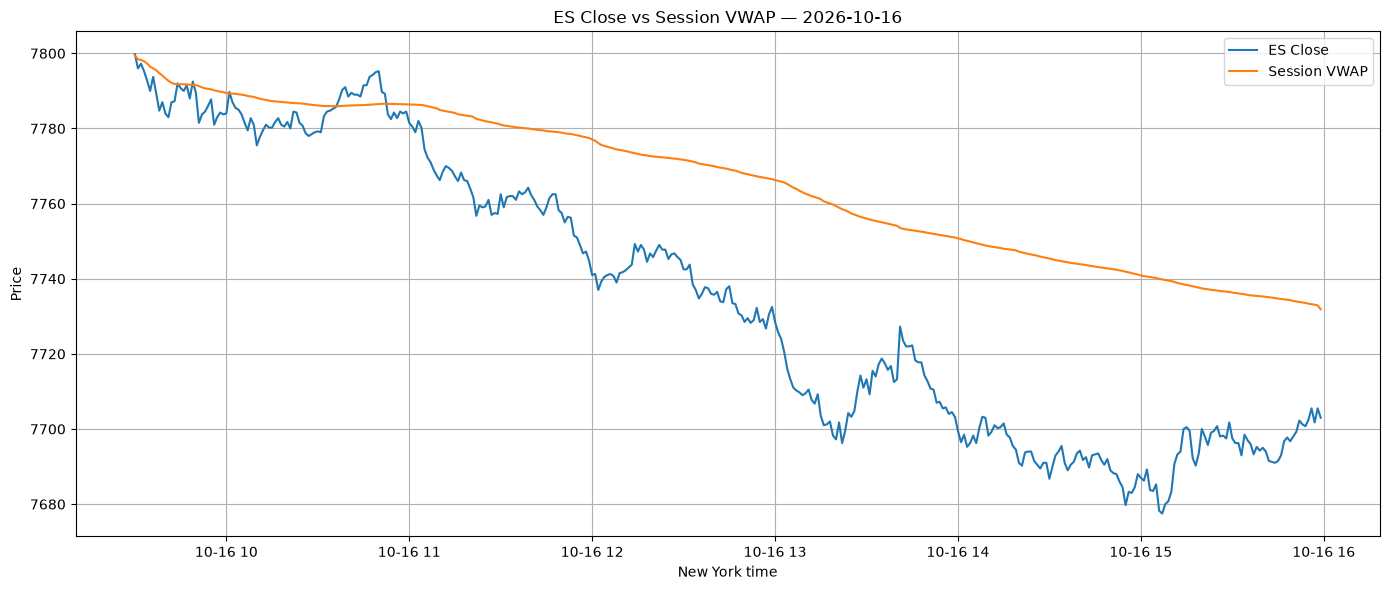

In [3]:
import matplotlib.pyplot as plt

latest_session = es_rth["sessions"].iloc[-1]
day = es_rth[es_rth["sessions"] == latest_session]

plt.figure(figsize=(14, 6))
plt.plot(day.index, day["close"], label="ES Close")
plt.plot(day.index, day["vwap"], label="Session VWAP")

plt.title(f"ES Close vs Session VWAP — {latest_session}")
plt.xlabel("New York time")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [4]:
bands = ind.calculate_vwap_bands()
bands.head()

,vwap,upper_1,lower_1,upper_2,lower_2,upper_3,lower_3
Datetime,,,,,,,
2026-10-09 09:30:00-04:00,7839.416667,7839.416667,7839.416667,7839.416667,7839.416667,7839.416667,7839.416667
2026-10-09 09:31:00-04:00,7838.801056,7839.636725,7837.965388,7840.472394,7837.129719,7841.308062,7836.294051
2026-10-09 09:32:00-04:00,7839.247320,7840.346879,7838.147762,7841.446437,7837.048203,7842.545996,7835.948645
2026-10-09 09:33:00-04:00,7839.738075,7841.220515,7838.255635,7842.702955,7836.773195,7844.185395,7835.290755
2026-10-09 09:34:00-04:00,7840.012419,7841.564656,7838.460183,7843.116892,7836.907947,7844.669129,7835.355710


In [5]:
ind = Indicator(load_data("ES=F"))
signals = ind.get_signal()
print(signals["long"].sum(), signals["short"].sum())

[*********************100%***********************]  1 of 1 completed

31 28


In [6]:
print(
    "Sessions with long signals:",
    es_rth.loc[signals["long"], "sessions"].nunique()
)

print(
    "Sessions with short signals:",
    es_rth.loc[signals["short"], "sessions"].nunique()
)

Sessions with long signals: 6
Sessions with short signals: 5


In [7]:
new_session = es_rth["sessions"].ne(es_rth["sessions"].shift())

long_starts = signals["long"] & (
    ~signals["long"].shift(1, fill_value=False) | new_session
)
short_starts = signals["short"] & (
    ~signals["short"].shift(1, fill_value=False) | new_session
)

print("Long signal episodes:", long_starts.sum())
print("Short signal episodes:", short_starts.sum())

Long signal episodes: 31
Short signal episodes: 28


In [8]:
bands.columns

Index(['vwap', 'upper_1', 'lower_1', 'upper_2', 'lower_2', 'upper_3',
       'lower_3'],
      dtype='str')

In [9]:
import numpy as np

events = es_rth.loc[
    long_starts | short_starts,
    ['close', 'sessions', 'vwap']
].copy()


events['signal'] = np.where(
    long_starts.loc[events.index],
    'long',
    'short'
)

events['timestamp'] = events.index

events['upper_2'] = bands.loc[events.index, 'upper_2'].copy()
events['lower_2'] = bands.loc[events.index, 'lower_2'].copy()





In [10]:
events.head()

,close,sessions,vwap,signal,timestamp,upper_2,lower_2
Datetime,,,,,,,
2026-10-09 09:32:00-04:00,7842.25,2026-10-09,7839.247320,short,2026-10-09 09:32:00-04:00,7841.446437,7837.048203
2026-10-09 09:43:00-04:00,7836.50,2026-10-09,7839.512073,long,2026-10-09 09:43:00-04:00,7842.419959,7836.604187
2026-10-09 09:46:00-04:00,7831.25,2026-10-09,7838.051364,long,2026-10-09 09:46:00-04:00,7844.550401,7831.552328
2026-10-09 09:48:00-04:00,7829.75,2026-10-09,7837.503277,long,2026-10-09 09:48:00-04:00,7844.877240,7830.129314
2026-10-09 10:51:00-04:00,7846.00,2026-10-09,7837.577053,short,2026-10-09 10:51:00-04:00,7844.517171,7830.636935


In [11]:
len(events)

59

In [12]:
long_lower_2 = events[(events['signal'] == 'long') & (events['close'] < events['lower_2'])]
short_upper_2 = events[(events['signal'] == 'short') & (events['close'] > events['upper_2'])]

len(long_lower_2), len(short_upper_2)


(31, 28)

In [13]:
length_val_long = len(long_lower_2)
length_val_short = len(short_upper_2)

inv_longs = np.sum(events['signal'] == 'long') - length_val_long
inv_short = np.sum(events['signal'] == 'short') - length_val_short

total_events = len(events)

inv_longs, inv_short, total_events


(np.int64(0), np.int64(0), 59)

In [14]:
length_val_long, length_val_short

(31, 28)

In [15]:
print(f"Invalid longs: {int(inv_longs)}")
print(f"Invalid shorts: {int(inv_short)}")

events.dropna()

events.head(5)

Invalid longs: 0
Invalid shorts: 0


,close,sessions,vwap,signal,timestamp,upper_2,lower_2
Datetime,,,,,,,
2026-10-09 09:32:00-04:00,7842.25,2026-10-09,7839.247320,short,2026-10-09 09:32:00-04:00,7841.446437,7837.048203
2026-10-09 09:43:00-04:00,7836.50,2026-10-09,7839.512073,long,2026-10-09 09:43:00-04:00,7842.419959,7836.604187
2026-10-09 09:46:00-04:00,7831.25,2026-10-09,7838.051364,long,2026-10-09 09:46:00-04:00,7844.550401,7831.552328
2026-10-09 09:48:00-04:00,7829.75,2026-10-09,7837.503277,long,2026-10-09 09:48:00-04:00,7844.877240,7830.129314
2026-10-09 10:51:00-04:00,7846.00,2026-10-09,7837.577053,short,2026-10-09 10:51:00-04:00,7844.517171,7830.636935


In [16]:
from event_study import EventStudy
import pandas as pd
import numpy as np

study = EventStudy(es_rth)
events = study.calculate_data()

print("Total events:", len(events))
print("\nEvents by direction:")
print(events["signal"].value_counts())

horizons = (5, 15, 30)

print("\nValid observations:")
for h in horizons:
    print(f"{h} bars: {events[f'return_{h}'].notna().sum()}")

print("\nForward directional price changes:")
for h in horizons:
    col = f"return_{h}"
    valid = events[col].dropna()

    print(f"\n{h}-bar horizon")
    print("Mean:", round(valid.mean(), 4))
    print("Median:", round(valid.median(), 4))
    print("Positive outcomes (%):", round((valid > 0).mean() * 100, 2))

print("\nStatistics by signal direction:")
for h in horizons:
    col = f"return_{h}"
    print(f"\n{h}-bar horizon")

    print(
        events.groupby("signal")[col].agg(
            ["count", "mean", "median"]
        )
    )

    print(
        "Positive outcomes (%):",
        (events.assign(positive=events[col] > 0)
         .groupby("signal")["positive"].mean() * 100).round(2)
    )

print("\nFirst five events:")
print(events.head())

return_cols = [f"return_{h}" for h in horizons]
print("\nInfinite values:", np.isinf(events[return_cols]).sum().sum())

Total events: 59

Events by direction:
signal
long     31
short    28
Name: count, dtype: int64

Valid observations:
5 bars: 59
15 bars: 59
30 bars: 59

Forward directional price changes:

5-bar horizon
Mean: 0.5636
Median: 0.75
Positive outcomes (%): 57.63

15-bar horizon
Mean: 1.4661
Median: 0.0
Positive outcomes (%): 47.46

30-bar horizon
Mean: 1.9364
Median: 0.5
Positive outcomes (%): 54.24

Statistics by signal direction:

5-bar horizon
        count      mean  median
signal                         
long       31 -0.282258    1.25
short      28  1.500000    0.75
Positive outcomes (%): signal
long     54.84
short    60.71
Name: positive, dtype: float64

15-bar horizon
        count      mean  median
signal                         
long       31  0.016129  -1.250
short      28  3.071429   0.125
Positive outcomes (%): signal
long     45.16
short    50.00
Name: positive, dtype: float64

30-bar horizon
        count      mean  median
signal                         
long       31 -0.064

In [17]:
import importlib
import event_study

importlib.reload(event_study)

EventStudy = event_study.EventStudy
study = EventStudy(es_rth)

events = study.calculate_data()

In [18]:
print("Total events:", len(events))

print("\nEvents by direction:")
print(events["signal"].value_counts())

for h in (5, 15, 30):
    col = f"return_{h}"
    valid = events[col].dropna()

    print(f"\n{'=' * 12} {h}-bar horizon {'=' * 12}")
    print("Valid observations:", len(valid))
    print("Mean directional change:", round(valid.mean(), 4), "points")
    print("Median directional change:", round(valid.median(), 4), "points")
    print("Positive outcomes:", round((valid > 0).mean() * 100, 2), "%")

    print("\nBy signal:")
    print(
        events.groupby("signal")[col]
        .agg(["count", "mean", "median"])
        .round(4)
    )

print("\nFirst 10 events:")
display(events.head(10))

Total events: 59

Events by direction:
signal
long     31
short    28
Name: count, dtype: int64

============ 5-bar horizon ============
Valid observations: 59
Mean directional change: 0.5636 points
Median directional change: 0.75 points
Positive outcomes: 57.63 %

By signal:
        count    mean  median
signal                       
long       31 -0.2823    1.25
short      28  1.5000    0.75

============ 15-bar horizon ============
Valid observations: 59
Mean directional change: 1.4661 points
Median directional change: 0.0 points
Positive outcomes: 47.46 %

By signal:
        count    mean  median
signal                       
long       31  0.0161  -1.250
short      28  3.0714   0.125

============ 30-bar horizon ============
Valid observations: 59
Mean directional change: 1.9364 points
Median directional change: 0.5 points
Positive outcomes: 54.24 %

By signal:
        count    mean  median
signal                       
long       31 -0.0645   0.000
short      28  4.1518   2.625



,close,sessions,vwap,signal,entry,timestamp,upper_2,lower_2,return_5,return_15,return_30
Datetime,,,,,,,,,,,
2026-10-09 09:32:00-04:00,7842.25,2026-10-09,7839.247320,short,7842.50,2026-10-09 09:32:00-04:00,7841.446437,7837.048203,3.75,9.75,6.75
2026-10-09 09:43:00-04:00,7836.50,2026-10-09,7839.512073,long,7836.75,2026-10-09 09:43:00-04:00,7842.419959,7836.604187,-6.75,-2.75,0.00
2026-10-09 09:46:00-04:00,7831.25,2026-10-09,7838.051364,long,7831.25,2026-10-09 09:46:00-04:00,7844.550401,7831.552328,1.75,1.75,8.25
2026-10-09 09:48:00-04:00,7829.75,2026-10-09,7837.503277,long,7830.00,2026-10-09 09:48:00-04:00,7844.877240,7830.129314,4.75,2.00,10.00
2026-10-09 10:51:00-04:00,7846.00,2026-10-09,7837.577053,short,7846.00,2026-10-09 10:51:00-04:00,7844.517171,7830.636935,-2.00,0.25,-5.75
2026-10-09 11:02:00-04:00,7849.50,2026-10-09,7838.705034,short,7849.50,2026-10-09 11:02:00-04:00,7847.963125,7829.446944,6.00,-1.50,4.00
2026-10-09 11:04:00-04:00,7849.25,2026-10-09,7839.029393,short,7849.25,2026-10-09 11:04:00-04:00,7848.791294,7829.267491,6.25,-2.25,4.75
2026-10-09 11:17:00-04:00,7851.00,2026-10-09,7839.609741,short,7851.00,2026-10-09 11:17:00-04:00,7849.776355,7829.443127,0.00,5.50,4.50
2026-10-09 12:16:00-04:00,7855.00,2026-10-09,7841.808047,short,7855.00,2026-10-09 12:16:00-04:00,7853.839290,7829.776804,0.75,-2.00,-3.50


In [19]:
import pandas as pd
import numpy as np

for h in (5, 15, 30):
    col = f"return_{h}"

    print(f"\n{'=' * 15} {h}-bar horizon {'=' * 15}")

    for direction in ("long", "short"):
        x = events.loc[events["signal"] == direction, col].dropna()

        print(
            f"{direction:5} | "
            f"n={len(x):2} | "
            f"mean={x.mean():+.4f} | "
            f"median={x.median():+.4f} | "
            f"win rate={(x > 0).mean() * 100:.2f}%"
        )

    x = events[col].dropna()
    print(
        f"ALL   | n={len(x):2} | "
        f"mean={x.mean():+.4f} | "
        f"median={x.median():+.4f} | "
        f"win rate={(x > 0).mean() * 100:.2f}%"
    )


=============== 5-bar horizon ===============
long  | n=31 | mean=-0.2823 | median=+1.2500 | win rate=54.84%
short | n=28 | mean=+1.5000 | median=+0.7500 | win rate=60.71%
ALL   | n=59 | mean=+0.5636 | median=+0.7500 | win rate=57.63%

=============== 15-bar horizon ===============
long  | n=31 | mean=+0.0161 | median=-1.2500 | win rate=45.16%
short | n=28 | mean=+3.0714 | median=+0.1250 | win rate=50.00%
ALL   | n=59 | mean=+1.4661 | median=+0.0000 | win rate=47.46%

=============== 30-bar horizon ===============
long  | n=31 | mean=-0.0645 | median=+0.0000 | win rate=48.39%
short | n=28 | mean=+4.1518 | median=+2.6250 | win rate=60.71%
ALL   | n=59 | mean=+1.9364 | median=+0.5000 | win rate=54.24%


In [20]:
import numpy as np
import pandas as pd

df = study.df
events = study.events.copy()

for h in (5, 15, 30):
    future_close = df["close"].shift(-h).reindex(events.index)
    future_session = df["sessions"].shift(-h).reindex(events.index)

    same_session = (
        events["sessions"].eq(future_session)
        & future_close.notna()
    )

    # Distance from price to VWAP when the signal occurs
    initial_distance = (
        events["close"] - events["vwap"]
    ).abs()

    # Distance from future price to the same, fixed VWAP target
    future_distance = (
        future_close - events["vwap"]
    ).abs()

    # Positive = price moved closer to the event-time VWAP
    progress = (initial_distance - future_distance).where(same_session)

    events[f"reversion_{h}"] = progress

print("VWAP reversion progress (ES points)")
print("Positive = closer to the VWAP target at the signal")

for h in (5, 15, 30):
    col = f"reversion_{h}"

    print(f"\n--- {h} bars ---")

    for direction in ("long", "short"):
        x = events.loc[events["signal"] == direction, col].dropna()

        print(
            f"{direction:5} | n={len(x):2} | "
            f"mean={x.mean():+.4f} | "
            f"median={x.median():+.4f} | "
            f"closer to VWAP={(x > 0).mean() * 100:.2f}%"
        )

    x = events[col].dropna()
    print(
        f"ALL   | n={len(x):2} | "
        f"mean={x.mean():+.4f} | "
        f"median={x.median():+.4f} | "
        f"closer to VWAP={(x > 0).mean() * 100:.2f}%"
    )

VWAP reversion progress (ES points)
Positive = closer to the VWAP target at the signal

--- 5 bars ---
long  | n=31 | mean=-1.2120 | median=+0.5250 | closer to VWAP=51.61%
short | n=28 | mean=+0.7233 | median=+0.7500 | closer to VWAP=60.71%
ALL   | n=59 | mean=-0.2935 | median=+0.7500 | closer to VWAP=55.93%

--- 15 bars ---
long  | n=31 | mean=-2.0384 | median=-2.0000 | closer to VWAP=38.71%
short | n=28 | mean=-1.9785 | median=-1.8750 | closer to VWAP=28.57%
ALL   | n=59 | mean=-2.0100 | median=-2.0000 | closer to VWAP=33.90%

--- 30 bars ---
long  | n=31 | mean=-2.0928 | median=-1.3441 | closer to VWAP=45.16%
short | n=28 | mean=-3.3199 | median=-2.5000 | closer to VWAP=35.71%
ALL   | n=59 | mean=-2.6751 | median=-1.5000 | closer to VWAP=40.68%


In [21]:
# Inspect event counts and mean VWAP reversion by trading session

for h in (5, 15, 30):
    col = f"reversion_{h}"

    print(f"\n{'=' * 12} {h}-bar horizon {'=' * 12}")

    daily = (
        events.groupby(["sessions", "signal"])[col]
        .agg(["count", "mean", "median"])
        .round(3)
    )

    print(daily)

print("\nNumber of distinct sessions:", events["sessions"].nunique())
print("\nEvents per session:")
print(events.groupby("sessions").size())


============ 5-bar horizon ============
                   count   mean  median
sessions   signal                      
2026-10-09 long        3 -0.083   1.750
           short      13  1.500   1.750
2026-10-12 long        5 -2.145  -1.250
           short       2  1.583   1.583
2026-10-13 long        6  0.222   1.500
           short       1 -5.000  -5.000
2026-10-14 long        6 -0.167   1.625
           short       4  2.146   1.473
2026-10-15 long        2  3.909   3.909
           short       8 -0.750  -1.250
2026-10-16 long        9 -3.861  -5.750

============ 15-bar horizon ============
                   count   mean  median
sessions   signal                      
2026-10-09 long        3  0.333   1.750
           short      13  0.039  -1.250
2026-10-12 long        5 -2.650  -3.000
           short       2 -3.161  -3.161
2026-10-13 long        6 -0.236   0.250
           short       1  0.000   0.000
2026-10-14 long        6  0.167   0.250
           short       4 -6.720  -9.0

In [22]:
from event_study import EventStudy

es = EventStudy(es_rth)
study = es.calculate_data()

study.head(10)



,close,sessions,vwap,signal,entry,timestamp,upper_2,lower_2,return_5,return_15,return_30
Datetime,,,,,,,,,,,
2026-10-09 09:32:00-04:00,7842.25,2026-10-09,7839.247320,short,7842.50,2026-10-09 09:32:00-04:00,7841.446437,7837.048203,3.75,9.75,6.75
2026-10-09 09:43:00-04:00,7836.50,2026-10-09,7839.512073,long,7836.75,2026-10-09 09:43:00-04:00,7842.419959,7836.604187,-6.75,-2.75,0.00
2026-10-09 09:46:00-04:00,7831.25,2026-10-09,7838.051364,long,7831.25,2026-10-09 09:46:00-04:00,7844.550401,7831.552328,1.75,1.75,8.25
2026-10-09 09:48:00-04:00,7829.75,2026-10-09,7837.503277,long,7830.00,2026-10-09 09:48:00-04:00,7844.877240,7830.129314,4.75,2.00,10.00
2026-10-09 10:51:00-04:00,7846.00,2026-10-09,7837.577053,short,7846.00,2026-10-09 10:51:00-04:00,7844.517171,7830.636935,-2.00,0.25,-5.75
2026-10-09 11:02:00-04:00,7849.50,2026-10-09,7838.705034,short,7849.50,2026-10-09 11:02:00-04:00,7847.963125,7829.446944,6.00,-1.50,4.00
2026-10-09 11:04:00-04:00,7849.25,2026-10-09,7839.029393,short,7849.25,2026-10-09 11:04:00-04:00,7848.791294,7829.267491,6.25,-2.25,4.75
2026-10-09 11:17:00-04:00,7851.00,2026-10-09,7839.609741,short,7851.00,2026-10-09 11:17:00-04:00,7849.776355,7829.443127,0.00,5.50,4.50
2026-10-09 12:16:00-04:00,7855.00,2026-10-09,7841.808047,short,7855.00,2026-10-09 12:16:00-04:00,7853.839290,7829.776804,0.75,-2.00,-3.50
